Cellule 1 : Environnement, Drive, graine

In [3]:
!pip -q install grad-cam

import torch, torch.nn as nn, numpy as np, random, time, os
import pandas as pd
import matplotlib.pyplot as plt
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Drive : une fenêtre demande l'autorisation, acceptez
from google.colab import drive
drive.mount("/content/drive")

DATA = "/content/data"                          # données : local (rapide)
OUT  = "/content/drive/MyDrive/eurosat_out"     # sorties : sur Drive (sauvegardées)
os.makedirs(OUT, exist_ok=True)

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)
if device == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))   # à noter dans le rapport
else:
    print("ATTENTION : pas de GPU, vérifiez le type d'exécution")

Mounted at /content/drive
Device : cpu
ATTENTION : pas de GPU, vérifiez le type d'exécution


Cellule 2 : Données et découpage 70/15/15

In [ ]:
SIZE = 128
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # normalisation ImageNet, identique pour tous

tf_train = transforms.Compose([
    transforms.Resize(SIZE),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.ToTensor(), transforms.Normalize(mean, std)])
tf_eval = transforms.Compose([
    transforms.Resize(SIZE),
    transforms.ToTensor(), transforms.Normalize(mean, std)])

ds_train = datasets.EuroSAT(DATA, download=True,  transform=tf_train)
ds_eval  = datasets.EuroSAT(DATA, download=False, transform=tf_eval)
classes = ds_train.classes
y = np.array(ds_train.targets)
print(len(y), "images |", classes)

idx = np.arange(len(y))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
va, te  = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=SEED)
print("train", len(tr), "| val", len(va), "| test", len(te))

def loader(ds, ids, shuffle):
    return DataLoader(Subset(ds, ids), batch_size=128, shuffle=shuffle,
                      num_workers=2, pin_memory=True)
dl_tr = loader(ds_train, tr, True)
dl_va = loader(ds_eval,  va, False)
dl_te = loader(ds_eval,  te, False)

100%|██████████| 94.3M/94.3M [00:00<00:00, 294MB/s]


27000 images | ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
train 18900 | val 4050 | test 4050


Cellule 3 : Exploration visuelle

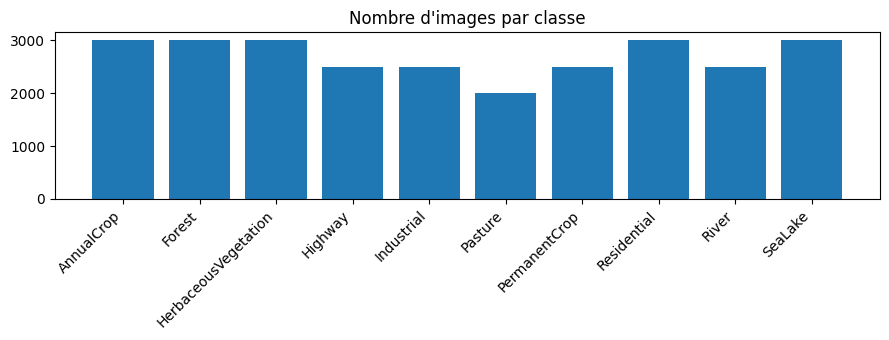

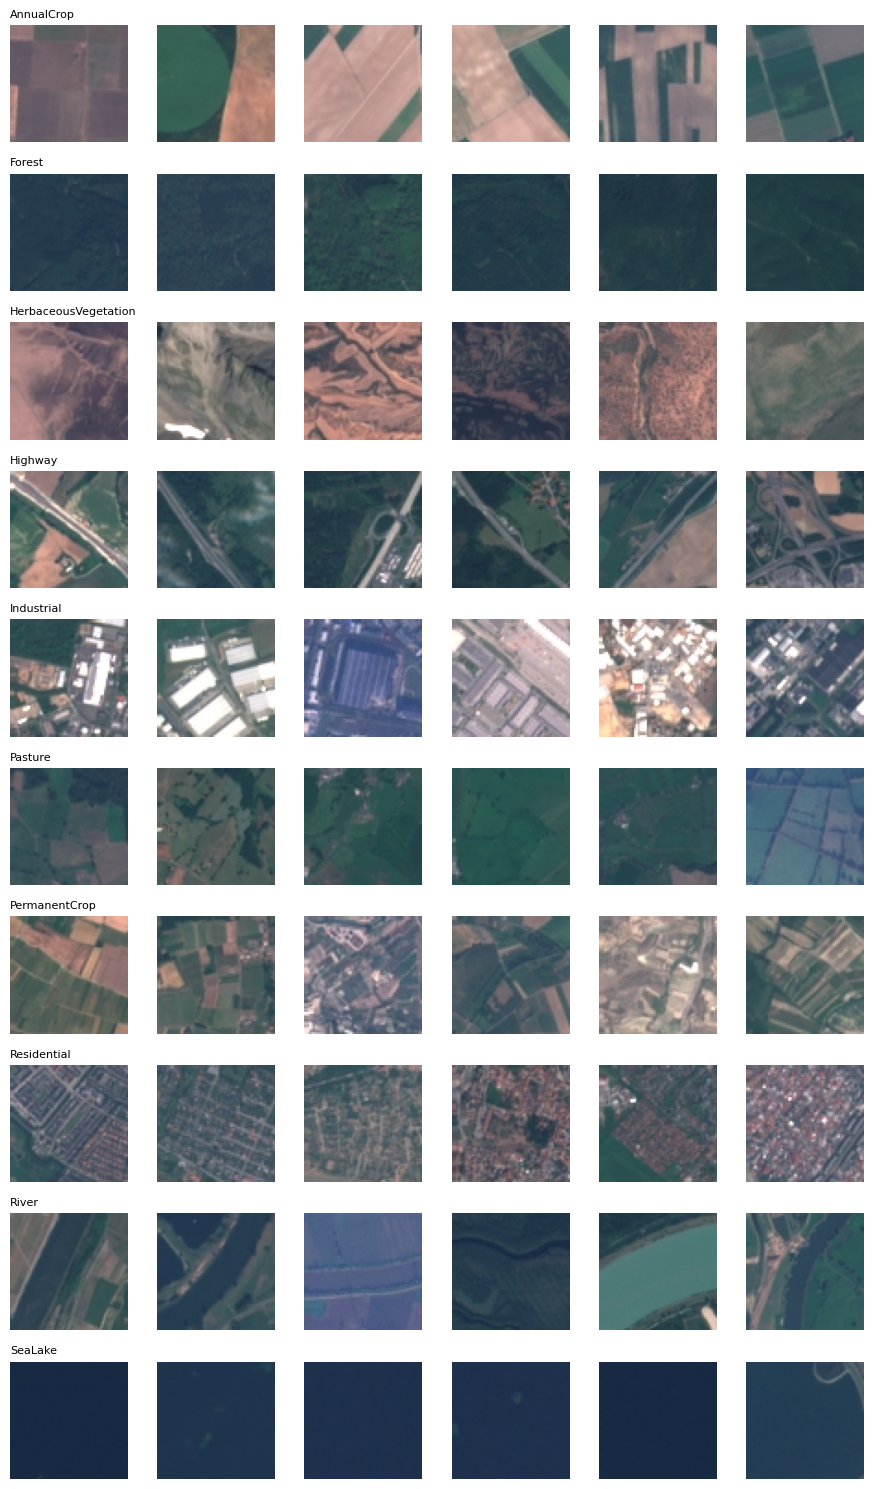

In [ ]:
plt.figure(figsize=(9,3.5))
plt.bar(classes, np.bincount(y)); plt.xticks(rotation=45, ha="right")
plt.title("Nombre d'images par classe"); plt.tight_layout()
plt.savefig(f"{OUT}/01_classes.png", dpi=150); plt.show()

raw = datasets.EuroSAT(DATA, download=False)     # images brutes, sans transformation
fig, axs = plt.subplots(10, 6, figsize=(9,15))
for c in range(10):
    for j, i in enumerate(np.where(y==c)[0][:6]):
        axs[c,j].imshow(raw[i][0]); axs[c,j].axis("off")
    axs[c,0].set_title(classes[c], fontsize=8, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT}/02_exemples.png", dpi=120); plt.show()

Cellule 4 : Fonctions d'entraînement et d'évaluation

In [ ]:
def run_epoch(model, dl, opt=None):
    train = opt is not None
    model.train(train)
    tot, correct, loss_sum = 0, 0, 0.0
    with torch.set_grad_enabled(train):
        for x, t in dl:
            x, t = x.to(device), t.to(device)
            out = model(x)
            loss = nn.functional.cross_entropy(out, t)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            loss_sum += loss.item() * len(t)
            correct  += (out.argmax(1) == t).sum().item()
            tot      += len(t)
    return loss_sum/tot, correct/tot

def fit(model, epochs, lr, name, hist=None):
    model.to(device)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    hist = hist or {"tl":[], "ta":[], "vl":[], "va":[], "time":0.0}
    if device == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for e in range(epochs):
        tl, ta = run_epoch(model, dl_tr, opt)
        vl, va_ = run_epoch(model, dl_va)
        for k, v in zip(["tl","ta","vl","va"], [tl, ta, vl, va_]):
            hist[k].append(v)
        print(f"{name} ép.{e+1}/{epochs} | train {ta:.3f} | val {va_:.3f}")
    if device == "cuda": torch.cuda.synchronize()
    hist["time"] += time.time() - t0
    return hist

def predict(model, dl):
    model.eval(); P, T = [], []
    with torch.no_grad():
        for x, t in dl:
            P += model(x.to(device)).argmax(1).cpu().tolist()
            T += t.tolist()
    return np.array(P), np.array(T)

Cellule 5 : Baseline (petit CNN depuis zéro)

In [ ]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o),
                         nn.ReLU(), nn.MaxPool2d(2))

seed_all()
baseline = nn.Sequential(block(3,32), block(32,64), block(64,128),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                         nn.Dropout(0.3), nn.Linear(128, 10))
h_base = fit(baseline, epochs=10, lr=1e-3, name="CNN")
torch.save(baseline.state_dict(), f"{OUT}/baseline.pt")

CNN ép.1/10 | train 0.629 | val 0.684
CNN ép.2/10 | train 0.714 | val 0.752
CNN ép.3/10 | train 0.753 | val 0.757
CNN ép.4/10 | train 0.773 | val 0.794
CNN ép.5/10 | train 0.789 | val 0.810
CNN ép.6/10 | train 0.801 | val 0.802
CNN ép.7/10 | train 0.810 | val 0.833
CNN ép.8/10 | train 0.811 | val 0.810
CNN ép.9/10 | train 0.825 | val 0.809
CNN ép.10/10 | train 0.830 | val 0.831


Cellule 6 : Transfer learning (ResNet18 et MobileNetV2)

In [ ]:
def build(name):
    if name == "resnet18":
        m = models.resnet18(weights="IMAGENET1K_V1")
        m.fc = nn.Linear(m.fc.in_features, 10); head = m.fc
    else:
        m = models.mobilenet_v2(weights="IMAGENET1K_V1")
        m.classifier[1] = nn.Linear(1280, 10); head = m.classifier
    return m, head

results = {}
for name in ["resnet18", "mobilenet_v2"]:
    seed_all()
    m, head = build(name)
    for p in m.parameters(): p.requires_grad = False     # phase 1 : tête seule
    for p in head.parameters(): p.requires_grad = True
    h = fit(m, epochs=3, lr=1e-3, name=name+" P1")
    for p in m.parameters(): p.requires_grad = True      # phase 2 : fine-tuning complet
    h = fit(m, epochs=7, lr=1e-4, name=name+" P2", hist=h)
    torch.save(m.state_dict(), f"{OUT}/{name}.pt")
    results[name] = (m, h)

results["baseline"] = (baseline, h_base)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s]


resnet18 P1 ép.1/3 | train 0.761 | val 0.862
resnet18 P1 ép.2/3 | train 0.881 | val 0.878
resnet18 P1 ép.3/3 | train 0.893 | val 0.893
resnet18 P2 ép.1/7 | train 0.952 | val 0.969
resnet18 P2 ép.2/7 | train 0.978 | val 0.973
resnet18 P2 ép.3/7 | train 0.982 | val 0.972
resnet18 P2 ép.4/7 | train 0.988 | val 0.974
resnet18 P2 ép.5/7 | train 0.991 | val 0.976
resnet18 P2 ép.6/7 | train 0.991 | val 0.981
resnet18 P2 ép.7/7 | train 0.993 | val 0.979
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 92.8MB/s]


mobilenet_v2 P1 ép.1/3 | train 0.838 | val 0.906
mobilenet_v2 P1 ép.2/3 | train 0.908 | val 0.920
mobilenet_v2 P1 ép.3/3 | train 0.920 | val 0.924
mobilenet_v2 P2 ép.1/7 | train 0.955 | val 0.970
mobilenet_v2 P2 ép.2/7 | train 0.978 | val 0.973
mobilenet_v2 P2 ép.3/7 | train 0.983 | val 0.974
mobilenet_v2 P2 ép.4/7 | train 0.989 | val 0.980
mobilenet_v2 P2 ép.5/7 | train 0.990 | val 0.980
mobilenet_v2 P2 ép.6/7 | train 0.993 | val 0.979
mobilenet_v2 P2 ép.7/7 | train 0.992 | val 0.979


Cellule 7 : Courbes d'apprentissage

In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(11,4))
for n, (m, h) in results.items():
    axs[0].plot(range(1, len(h["vl"])+1), h["vl"], label=n)
    axs[1].plot(range(1, len(h["va"])+1), h["va"], label=n)
axs[0].set_title("Loss (validation)"); axs[1].set_title("Accuracy (validation)")
for a in axs: a.legend(); a.set_xlabel("époque")
plt.tight_layout(); plt.savefig(f"{OUT}/03_courbes.png", dpi=150); plt.show()

Cellule 8 : Choix sur la validation, puis test (une seule fois)

In [ ]:
best = max(results, key=lambda k: results[k][1]["va"][-1])   # choix sur la VALIDATION
print("Meilleur modèle (validation) :", best)

summary, preds = {}, {}
for n, (m, h) in results.items():
    P, T = predict(m, dl_te)            # test : un seul passage par modèle
    preds[n] = (P, T)
    summary[n] = dict(val_acc=h["va"][-1], test_acc=(P==T).mean(),
                      time_min=h["time"]/60,
                      params_M=sum(p.numel() for p in m.parameters())/1e6)
    print(f"\n=== {n} | test acc = {summary[n]['test_acc']:.4f}")
    print(classification_report(T, P, target_names=classes, digits=3))

P, T = preds[best]
fig, ax = plt.subplots(figsize=(8,8))
ConfusionMatrixDisplay(confusion_matrix(T, P), display_labels=classes).plot(
    ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title(f"Matrice de confusion : {best}"); plt.tight_layout()
plt.savefig(f"{OUT}/04_confusion.png", dpi=150); plt.show()

cm = confusion_matrix(T, P); np.fill_diagonal(cm, 0)
pairs = sorted([(cm[i,j], classes[i], classes[j]) for i in range(10) for j in range(10) if cm[i,j]>0],
               reverse=True)[:5]
for n_, a, b in pairs: print(f"{n_:3d} images : vrai {a}  →  prédit {b}")

Cellule 9 : Coût de calcul par point de précision

In [ ]:
df = pd.DataFrame(summary).T
b = df.loc["baseline"]
df["gain_points"] = (df.test_acc - b.test_acc) * 100
df["min_en_plus"] = df.time_min - b.time_min
df["min_par_point"] = df.min_en_plus / df.gain_points
df.loc["baseline", "min_par_point"] = np.nan
print(df.round(3)); df.round(4).to_csv(f"{OUT}/resultats.csv")

plt.figure(figsize=(6,4.5))
for n, r in summary.items():
    plt.scatter(r["time_min"], r["test_acc"]*100, s=r["params_M"]*40+40, label=n, alpha=.8)
plt.xlabel("temps d'entraînement (min)"); plt.ylabel("accuracy test (%)")
plt.title("Précision vs coût de calcul (taille = nb de paramètres)")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{OUT}/05_cout.png", dpi=150); plt.show()

Cellule 10 : Grad-CAM (ResNet18)

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

model = results["resnet18"][0].eval()
cam = GradCAM(model=model, target_layers=[model.layer4[-1]])
inv = lambda t: (t.cpu().numpy().transpose(1,2,0)*np.array(std)+np.array(mean)).clip(0,1)

xs, ts = next(iter(dl_te))
with torch.no_grad(): pr = model(xs.to(device)).argmax(1).cpu()

fig, axs = plt.subplots(2, 8, figsize=(16,4.8))
for i in range(8):
    g = cam(input_tensor=xs[i:i+1].to(device))[0]
    axs[0,i].imshow(inv(xs[i])); axs[0,i].axis("off")
    axs[1,i].imshow(show_cam_on_image(inv(xs[i]).astype(np.float32), g, use_rgb=True)); axs[1,i].axis("off")
    axs[0,i].set_title(f"vrai: {classes[ts[i]][:9]}\nprédit: {classes[pr[i]][:9]}", fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/06_gradcam.png", dpi=150); plt.show()

Cellule 11 : Images mal classées

In [ ]:
P, T = preds["resnet18"]
wrong = np.where(P != T)[0]
print(len(wrong), "erreurs sur", len(T))

fig, axs = plt.subplots(2, 4, figsize=(12,6.5))
for ax, k in zip(axs.ravel(), wrong[:8]):
    ax.imshow(raw[te[k]][0]); ax.axis("off")      # te = même ordre que dl_te
    ax.set_title(f"vrai: {classes[T[k]]}\nprédit: {classes[P[k]]}", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/07_erreurs.png", dpi=150); plt.show()

Cellule 12 (optionnelle) : 3 graines, moyenne ± écart-type

In [ ]:
def train_one(name, seed):
    seed_all(seed)
    if name == "baseline":
        m = nn.Sequential(block(3,32), block(32,64), block(64,128), nn.AdaptiveAvgPool2d(1),
                          nn.Flatten(), nn.Dropout(0.3), nn.Linear(128,10))
        h = fit(m, 10, 1e-3, f"{name}-s{seed}")
    else:
        m, head = build(name)
        for p in m.parameters(): p.requires_grad = False
        for p in head.parameters(): p.requires_grad = True
        h = fit(m, 3, 1e-3, f"{name}-s{seed} P1")
        for p in m.parameters(): p.requires_grad = True
        h = fit(m, 7, 1e-4, f"{name}-s{seed} P2", hist=h)
    return h["va"][-1]

multi = {n: [train_one(n, s) for s in (42, 43, 44)] for n in ["baseline", "resnet18", "mobilenet_v2"]}
for n, v in multi.items():
    print(f"{n:13s} val acc = {np.mean(v)*100:.2f} ± {np.std(v)*100:.2f} %")